# 16 - Dataset Subsets: Slicing WLASL2000 for Progressive Training

## Goal

Read the clean landmark metadata from Notebook 15 and generate **"VIP list" JSON files**
that tell the PyTorch DataLoader exactly which samples to use for each experiment.
No files are copied — the JSONs simply point to the existing `.npy` files.

## Subsets to generate

| File | Selection rule | Purpose |
|------|---------------|---------|
| `wlasl_100_subset.json` | Top-100 glosses by total videos | Controlled baseline |
| `wlasl_300_subset.json` | Top-300 glosses | Medium scale |
| `wlasl_500_subset.json` | Top-500 glosses | Medium-large scale |
| `wlasl_700_subset.json` | Top-700 glosses | Large scale step |
| `wlasl_900_subset.json` | Top-900 glosses | Pre-1k scale |
| `wlasl_1000_subset.json` | Top-1000 glosses | Large scale |
| `wlasl_1200_subset.json` | Top-1200 glosses | Extended scale |
| `wlasl_1500_subset.json` | Top-1500 glosses | Near-full scale |
| `wlasl_clean_full.json` | All glosses with **≥ 5** videos | Maximum data, quality floor |

## Design decision

The subset JSONs store **flat sample lists** `{path, gloss, gloss_idx}` so the DataLoader
needs zero extra logic — just load the JSON and iterate.

## Output directory

```
06_datasets/wlasl/subsets/
├── wlasl_100_subset.json
├── wlasl_300_subset.json
├── wlasl_500_subset.json
├── wlasl_700_subset.json
├── wlasl_900_subset.json
├── wlasl_1000_subset.json
├── wlasl_1200_subset.json
├── wlasl_1500_subset.json
└── wlasl_clean_full.json
```

In [1]:
# === 1. Imports and Paths ===

import json
import numpy as np
from pathlib import Path
from collections import defaultdict
from typing import Dict, List, Tuple
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

# Paths
BASE = Path("/home/fransando/Dev/tfg-sign-language-recognition")
LANDMARKS_ROOT = BASE / "06_datasets" / "wlasl" / "landmarks" / "wlasl2000"
METADATA_PATH = LANDMARKS_ROOT / "metadata.json"
OUTPUT_DIR = BASE / "06_datasets" / "wlasl" / "subsets"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"Landmarks root: {LANDMARKS_ROOT}")
print(f"Output dir: {OUTPUT_DIR}")
print(f"Metadata exists: {METADATA_PATH.exists()}")

Date: 2026-03-11 01:06
Landmarks root: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl2000
Output dir: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/subsets
Metadata exists: True


In [2]:
# === 2. Load Metadata and Build Gloss Ranking ===

with open(METADATA_PATH) as f:
    metadata = json.load(f)

per_gloss_counts = metadata["per_gloss_counts"]

# Build ranked list: (gloss, total, train, val, test), sorted by total desc
gloss_ranking = sorted(
    [
        {
            "gloss": g,
            "total": v["total"],
            "train": v["train"],
            "val": v["val"],
            "test": v["test"],
        }
        for g, v in per_gloss_counts.items()
    ],
    key=lambda x: (-x["total"], x["gloss"]),  # tie-break alphabetically
)

totals = [g["total"] for g in gloss_ranking]

print("=" * 60)
print("WLASL2000 LANDMARK DATASET - OVERVIEW")
print("=" * 60)
print(f"Total glosses:      {len(gloss_ranking):>6}")
print(f"Total .npy files:   {metadata['statistics']['total_npy_files']:>6}")
print(f"  Train:            {metadata['statistics']['by_split']['train']:>6}")
print(f"  Val:              {metadata['statistics']['by_split']['val']:>6}")
print(f"  Test:             {metadata['statistics']['by_split']['test']:>6}")
print(f"")
print(f"Videos per gloss:")
print(f"  Min:    {min(totals):>6}")
print(f"  Max:    {max(totals):>6}")
print(f"  Mean:   {sum(totals)/len(totals):>6.1f}")
print(f"  Median: {sorted(totals)[len(totals)//2]:>6}")
print(f"")
print(f"Mean detection rate: {metadata['statistics']['mean_detection_rate']:.1%}")
print(f"Processing success:  {metadata['statistics']['success_rate']:.1%} "
      f"({metadata['statistics']['total_success']}/{metadata['statistics']['total_processed']})")
print(f"")
print(f"Top 10 richest glosses:")
for i, g in enumerate(gloss_ranking[:10]):
    print(f"  {i+1:2d}. {g['gloss']:<20} total={g['total']:2d} "
          f"(train={g['train']}, val={g['val']}, test={g['test']})")

WLASL2000 LANDMARK DATASET - OVERVIEW
Total glosses:        2000
Total .npy files:    11844
  Train:              8210
  Val:                2232
  Test:               1402

Videos per gloss:
  Min:         2
  Max:        16
  Mean:      5.9
  Median:      6

Mean detection rate: 68.0%
Processing success:  98.9% (11844/11980)

Top 10 richest glosses:
   1. cool                 total=16 (train=11, val=3, test=2)
   2. thin                 total=16 (train=11, val=3, test=2)
   3. before               total=15 (train=11, val=1, test=3)
   4. drink                total=15 (train=11, val=3, test=1)
   5. go                   total=15 (train=11, val=3, test=1)
   6. computer             total=14 (train=10, val=3, test=1)
   7. cousin               total=14 (train=9, val=3, test=2)
   8. help                 total=14 (train=10, val=2, test=2)
   9. who                  total=14 (train=10, val=3, test=1)
  10. accident             total=13 (train=9, val=2, test=2)


In [3]:
# === 3. Distribution Analysis ===

print("=" * 60)
print("LONG-TAIL DISTRIBUTION ANALYSIS")
print("=" * 60)
print(f"{'Min videos':>15} {'Glosses':>10} {'Videos':>10} {'Coverage':>10}")
print("-" * 50)

total_videos = sum(totals)
for threshold in [1, 2, 3, 5, 7, 10, 12, 15]:
    n_glosses = sum(1 for v in totals if v >= threshold)
    n_videos = sum(v for v in totals if v >= threshold)
    pct = n_videos / total_videos * 100
    print(f"{f'>= {threshold}':>15} {n_glosses:>10} {n_videos:>10} {pct:>9.1f}%")

print(f"\nKey thresholds for training:")
for threshold in [5]:
    above = sum(1 for v in totals if v >= threshold)
    below = sum(1 for v in totals if v < threshold)
    print(f"  >= {threshold}: {above} glosses kept, {below} discarded (quality floor)")

# Coefficient of variation (imbalance metric)
arr = np.array(totals)
cv = arr.std() / arr.mean() * 100
print(f"\nClass imbalance: CV = {cv:.1f}% (lower = more balanced)")

LONG-TAIL DISTRIBUTION ANALYSIS
     Min videos    Glosses     Videos   Coverage
--------------------------------------------------
           >= 1       2000      11844     100.0%
           >= 2       2000      11844     100.0%
           >= 3       1984      11812      99.7%
           >= 5       1544      10147      85.7%
           >= 7        638       5217      44.0%
          >= 10        100       1113       9.4%
          >= 12         28        369       3.1%
          >= 15          5         77       0.7%

Key thresholds for training:
  >= 5: 1544 glosses kept, 456 discarded (quality floor)

Class imbalance: CV = 32.9% (lower = more balanced)


In [4]:
# === 4. Build File Index (scan actual .npy files on disk) ===
#
# We need the actual video IDs (file names) for each gloss/split.
# The metadata only has counts, so we scan the filesystem.

file_index = defaultdict(lambda: {"train": [], "val": [], "test": []})

for split in ["train", "val", "test"]:
    split_dir = LANDMARKS_ROOT / split
    if not split_dir.exists():
        continue
    for gloss_dir in sorted(split_dir.iterdir()):
        if not gloss_dir.is_dir():
            continue
        gloss = gloss_dir.name
        for npy_file in sorted(gloss_dir.glob("*.npy")):
            # Store path relative to LANDMARKS_ROOT
            rel_path = str(npy_file.relative_to(LANDMARKS_ROOT))
            file_index[gloss][split].append(rel_path)

# Verify against metadata counts
mismatches = 0
for gloss, counts in per_gloss_counts.items():
    for split in ["train", "val", "test"]:
        on_disk = len(file_index[gloss][split])
        in_meta = counts[split]
        if on_disk != in_meta:
            mismatches += 1

total_indexed = sum(
    len(file_index[g][s])
    for g in file_index
    for s in ["train", "val", "test"]
)

print(f"File index built:")
print(f"  Glosses indexed: {len(file_index)}")
print(f"  Total files: {total_indexed}")
print(f"  Metadata mismatches: {mismatches} (should be 0)")

File index built:
  Glosses indexed: 2000
  Total files: 11844
  Metadata mismatches: 0 (should be 0)


In [5]:
# === 5. Quality Issues: Flag Problematic Glosses ===

print("=" * 65)
print("QUALITY FLAGS")
print("=" * 65)

# Glosses with val=0 in each subset
for subset_n, subset_glosses in [
    ("Top-100",  gloss_ranking[:100]),
    ("Top-300",  gloss_ranking[:300]),
    ("Top-500",  gloss_ranking[:500]),
    ("Top-700",  gloss_ranking[:700]),
    ("Top-900",  gloss_ranking[:900]),
    ("Top-1000", gloss_ranking[:1000]),
    ("Top-1200", gloss_ranking[:1200]),
    ("Top-1500", gloss_ranking[:1500]),
]:
    no_val = [g["gloss"] for g in subset_glosses if g["val"] == 0]
    no_test = [g["gloss"] for g in subset_glosses if g["test"] == 0]
    print(f"\n{subset_n}:")
    print(f"  Glosses with val=0:  {len(no_val):4d}", end="")
    if no_val:
        print(f"  -> {', '.join(no_val[:5])}{'...' if len(no_val) > 5 else ''}")
    else:
        print(" (none)")
    print(f"  Glosses with test=0: {len(no_test):4d}", end="")
    if no_test:
        print(f"  -> {', '.join(no_test[:5])}{'...' if len(no_test) > 5 else ''}")
    else:
        print(" (none)")

# Glosses with val=0 in clean_full (>=5)
clean_glosses = [g for g in gloss_ranking if g["total"] >= 5]
no_val_clean = [g["gloss"] for g in clean_glosses if g["val"] == 0]
no_test_clean = [g["gloss"] for g in clean_glosses if g["test"] == 0]
print(f"\nClean-full (>=5):")
print(f"  Glosses with val=0:  {len(no_val_clean):4d}")
print(f"  Glosses with test=0: {len(no_test_clean):4d}")

print(f"\nNOTE: Glosses with val=0 will have no validation signal.")
print(f"This is a known WLASL dataset property, not a processing bug.")
print(f"The DataLoader must handle empty splits gracefully.")

QUALITY FLAGS

Top-100:
  Glosses with val=0:     3  -> corn, study, walk
  Glosses with test=0:   14  -> bed, man, apple, family, later...

Top-300:
  Glosses with val=0:    24  -> corn, study, walk, class, dirty...
  Glosses with test=0:   48  -> bed, man, apple, family, later...

Top-500:
  Glosses with val=0:    49  -> corn, study, walk, class, dirty...
  Glosses with test=0:   87  -> bed, man, apple, family, later...

Top-700:
  Glosses with val=0:    71  -> corn, study, walk, class, dirty...
  Glosses with test=0:  145  -> bed, man, apple, family, later...

Top-900:
  Glosses with val=0:    99  -> corn, study, walk, class, dirty...
  Glosses with test=0:  225  -> bed, man, apple, family, later...

Top-1000:
  Glosses with val=0:   107  -> corn, study, walk, class, dirty...
  Glosses with test=0:  270  -> bed, man, apple, family, later...

Top-1200:
  Glosses with val=0:   136  -> corn, study, walk, class, dirty...
  Glosses with test=0:  363  -> bed, man, apple, family, later...


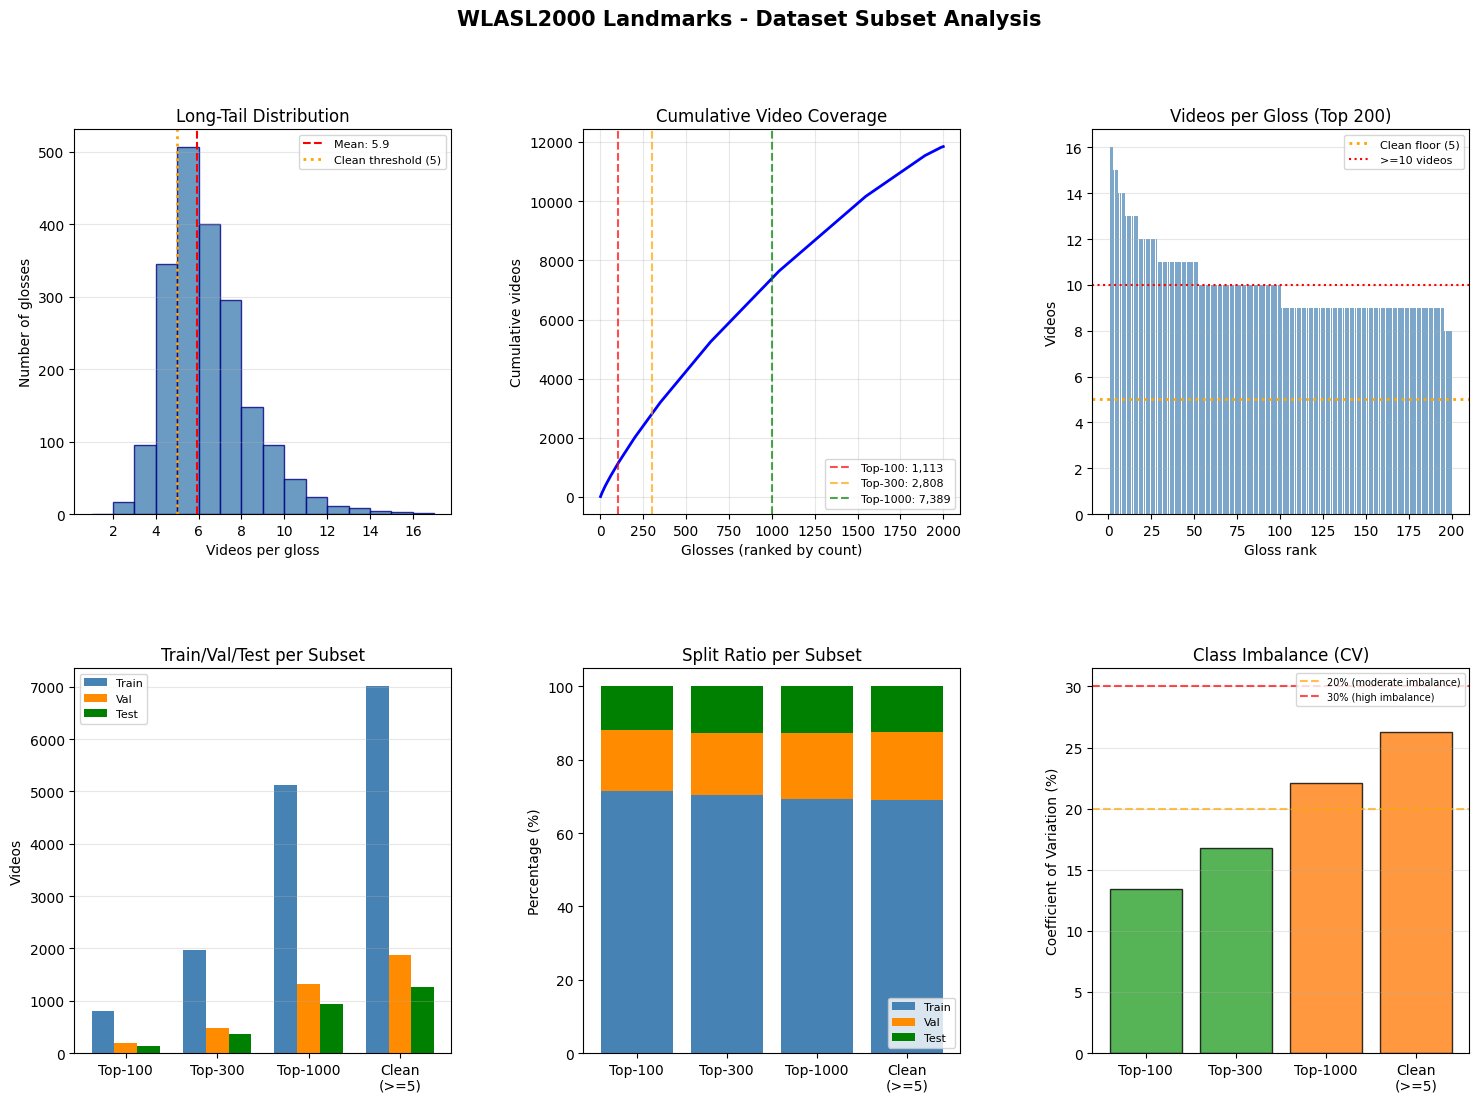

Chart saved to: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/subsets/subset_analysis.png


In [6]:
# === 6. Visualizations ===

fig = plt.figure(figsize=(18, 12))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

# ---- 1. Long-tail histogram ----
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(totals, bins=range(1, max(totals) + 2), color='steelblue', edgecolor='navy', alpha=0.8)
ax1.axvline(np.mean(totals), color='red', linestyle='--', label=f'Mean: {np.mean(totals):.1f}')
ax1.axvline(5, color='orange', linestyle=':', linewidth=2, label='Clean threshold (5)')
ax1.set_xlabel('Videos per gloss')
ax1.set_ylabel('Number of glosses')
ax1.set_title('Long-Tail Distribution')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3, axis='y')

# ---- 2. Cumulative coverage curve ----
ax2 = fig.add_subplot(gs[0, 1])
sorted_desc = sorted(totals, reverse=True)
cumulative = np.cumsum(sorted_desc)
ax2.plot(range(1, len(sorted_desc) + 1), cumulative, 'b-', linewidth=2)
for mark_n, color in [(100, 'red'), (300, 'orange'), (1000, 'green')]:
    if mark_n <= len(sorted_desc):
        ax2.axvline(mark_n, color=color, linestyle='--', alpha=0.7,
                    label=f'Top-{mark_n}: {cumulative[mark_n-1]:,}')
ax2.set_xlabel('Glosses (ranked by count)')
ax2.set_ylabel('Cumulative videos')
ax2.set_title('Cumulative Video Coverage')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

# ---- 3. Videos per gloss (sorted descending, first 200) ----
ax3 = fig.add_subplot(gs[0, 2])
x = range(1, 201)
y = sorted_desc[:200]
ax3.bar(x, y, color='steelblue', alpha=0.7)
ax3.axhline(5, color='orange', linestyle=':', linewidth=2, label='Clean floor (5)')
ax3.axhline(10, color='red', linestyle=':', linewidth=1.5, label='>=10 videos')
ax3.set_xlabel('Gloss rank')
ax3.set_ylabel('Videos')
ax3.set_title('Videos per Gloss (Top 200)')
ax3.legend(fontsize=8)
ax3.grid(True, alpha=0.3, axis='y')

# ---- 4. Subset comparison: train/val/test bars ----
ax4 = fig.add_subplot(gs[1, 0])
subset_labels = ['Top-100', 'Top-300', 'Top-1000', 'Clean\n(>=5)']
subset_configs = [
    gloss_ranking[:100],
    gloss_ranking[:300],
    gloss_ranking[:1000],
    [g for g in gloss_ranking if g['total'] >= 5],
]
train_counts = [sum(g['train'] for g in s) for s in subset_configs]
val_counts   = [sum(g['val']   for g in s) for s in subset_configs]
test_counts  = [sum(g['test']  for g in s) for s in subset_configs]

x = np.arange(len(subset_labels))
w = 0.25
ax4.bar(x - w, train_counts, w, label='Train', color='steelblue')
ax4.bar(x,     val_counts,   w, label='Val',   color='darkorange')
ax4.bar(x + w, test_counts,  w, label='Test',  color='green')
ax4.set_xticks(x)
ax4.set_xticklabels(subset_labels)
ax4.set_ylabel('Videos')
ax4.set_title('Train/Val/Test per Subset')
ax4.legend(fontsize=8)
ax4.grid(True, alpha=0.3, axis='y')

# ---- 5. Train/val/test ratio per subset ----
ax5 = fig.add_subplot(gs[1, 1])
totals_per_subset = [tr + v + te for tr, v, te in zip(train_counts, val_counts, test_counts)]
train_pct = [tr / tot * 100 for tr, tot in zip(train_counts, totals_per_subset)]
val_pct   = [v  / tot * 100 for v,  tot in zip(val_counts,   totals_per_subset)]
test_pct  = [te / tot * 100 for te, tot in zip(test_counts,  totals_per_subset)]

bars_train = ax5.bar(x, train_pct, label='Train', color='steelblue')
bars_val   = ax5.bar(x, val_pct,   bottom=train_pct, label='Val', color='darkorange')
bars_test  = ax5.bar(x, test_pct,
                     bottom=[tr + v for tr, v in zip(train_pct, val_pct)],
                     label='Test', color='green')
ax5.set_xticks(x)
ax5.set_xticklabels(subset_labels)
ax5.set_ylabel('Percentage (%)')
ax5.set_title('Split Ratio per Subset')
ax5.legend(fontsize=8, loc='lower right')
ax5.set_ylim(0, 105)

# ---- 6. Class balance: CV per subset ----
ax6 = fig.add_subplot(gs[1, 2])
cv_per_subset = []
for s in subset_configs:
    t = np.array([g['total'] for g in s])
    cv_per_subset.append(t.std() / t.mean() * 100)
colors_cv = ['#d62728' if cv > 30 else '#ff7f0e' if cv > 20 else '#2ca02c' for cv in cv_per_subset]
ax6.bar(subset_labels, cv_per_subset, color=colors_cv, alpha=0.8, edgecolor='black')
ax6.axhline(20, color='orange', linestyle='--', alpha=0.7, label='20% (moderate imbalance)')
ax6.axhline(30, color='red',    linestyle='--', alpha=0.7, label='30% (high imbalance)')
ax6.set_ylabel('Coefficient of Variation (%)')
ax6.set_title('Class Imbalance (CV)')
ax6.legend(fontsize=7)
ax6.grid(True, alpha=0.3, axis='y')

plt.suptitle('WLASL2000 Landmarks - Dataset Subset Analysis', fontsize=15, fontweight='bold')
plt.savefig(OUTPUT_DIR / 'subset_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Chart saved to: {OUTPUT_DIR / 'subset_analysis.png'}")

In [7]:
# === 7. Subset Builder Function ===

def build_subset(
    ranked_glosses: List[Dict],
    file_index: Dict,
    name: str,
    description: str,
    landmarks_root: Path,
) -> Dict:
    """
    Build a subset dictionary ready to be saved as JSON.

    The 'samples' field contains flat lists of {path, gloss, gloss_idx}
    so a DataLoader can use it directly:

        with open('wlasl_100_subset.json') as f:
            subset = json.load(f)
        train_samples = subset['samples']['train']
        # each item: {"path": "train/cool/69241.npy", "gloss": "cool", "gloss_idx": 0}
    """
    # Assign sequential indices (sorted alphabetically for reproducibility)
    glosses_sorted = sorted(g["gloss"] for g in ranked_glosses)
    gloss_to_idx = {g: i for i, g in enumerate(glosses_sorted)}
    idx_to_gloss = {str(i): g for i, g in enumerate(glosses_sorted)}

    gloss_set = set(g["gloss"] for g in ranked_glosses)

    # Build flat sample lists per split
    samples = {"train": [], "val": [], "test": []}
    per_class_counts = {}

    for gloss in glosses_sorted:
        if gloss not in gloss_set:
            continue
        idx = gloss_to_idx[gloss]
        per_class_counts[gloss] = {"train": 0, "val": 0, "test": 0}

        for split in ["train", "val", "test"]:
            for path in file_index[gloss][split]:
                samples[split].append({
                    "path": path,
                    "gloss": gloss,
                    "gloss_idx": idx,
                })
                per_class_counts[gloss][split] += 1

    # Statistics
    total_counts = [
        sum(per_class_counts[g][s] for s in ["train", "val", "test"])
        for g in glosses_sorted
    ]
    arr = np.array(total_counts)

    return {
        "name": name,
        "description": description,
        "created": datetime.now().strftime("%Y-%m-%d %H:%M"),
        "source": "wlasl2000_landmarks",
        "landmarks_root": str(landmarks_root),
        "num_classes": len(glosses_sorted),
        "statistics": {
            "total": int(arr.sum()),
            "train": len(samples["train"]),
            "val":   len(samples["val"]),
            "test":  len(samples["test"]),
            "train_pct": round(len(samples["train"]) / max(int(arr.sum()), 1) * 100, 1),
            "val_pct":   round(len(samples["val"])   / max(int(arr.sum()), 1) * 100, 1),
            "test_pct":  round(len(samples["test"])  / max(int(arr.sum()), 1) * 100, 1),
            "min_videos_per_class": int(arr.min()),
            "max_videos_per_class": int(arr.max()),
            "mean_videos_per_class": round(float(arr.mean()), 2),
            "std_videos_per_class":  round(float(arr.std()),  2),
            "cv_pct": round(float(arr.std() / arr.mean() * 100), 1),  # class imbalance
            "classes_with_no_val":  sum(1 for g in glosses_sorted if per_class_counts[g]["val"]  == 0),
            "classes_with_no_test": sum(1 for g in glosses_sorted if per_class_counts[g]["test"] == 0),
        },
        "glosses": glosses_sorted,
        "gloss_to_idx": gloss_to_idx,
        "idx_to_gloss": idx_to_gloss,
        "per_class_counts": per_class_counts,
        "samples": samples,
    }


print("build_subset() defined.")

build_subset() defined.


In [8]:
# === 8. Generate the Four Subsets ===

subset_definitions = [
    {
        "name": "wlasl_100",
        "glosses": gloss_ranking[:100],
        "description": "Top-100 glosses by total landmark videos (most data-rich)",
        "filename": "wlasl_100_subset.json",
    },
    {
        "name": "wlasl_300",
        "glosses": gloss_ranking[:300],
        "description": "Top-300 glosses by total landmark videos",
        "filename": "wlasl_300_subset.json",
    },
    {
        "name": "wlasl_500",
        "glosses": gloss_ranking[:500],
        "description": "Top-500 glosses by total landmark videos",
        "filename": "wlasl_500_subset.json",
    },
    {
        "name": "wlasl_700",
        "glosses": gloss_ranking[:700],
        "description": "Top-700 glosses by total landmark videos",
        "filename": "wlasl_700_subset.json",
    },
    {
        "name": "wlasl_900",
        "glosses": gloss_ranking[:900],
        "description": "Top-900 glosses by total landmark videos",
        "filename": "wlasl_900_subset.json",
    },
    {
        "name": "wlasl_1000",
        "glosses": gloss_ranking[:1000],
        "description": "Top-1000 glosses by total landmark videos",
        "filename": "wlasl_1000_subset.json",
    },
    {
        "name": "wlasl_1200",
        "glosses": gloss_ranking[:1200],
        "description": "Top-1200 glosses by total landmark videos",
        "filename": "wlasl_1200_subset.json",
    },
    {
        "name": "wlasl_1500",
        "glosses": gloss_ranking[:1500],
        "description": "Top-1500 glosses by total landmark videos",
        "filename": "wlasl_1500_subset.json",
    },
    {
        "name": "wlasl_clean_full",
        "glosses": [g for g in gloss_ranking if g["total"] >= 5],
        "description": "All glosses with >= 5 landmark videos (quality floor)",
        "filename": "wlasl_clean_full.json",
    },
]

built_subsets = {}

for defn in subset_definitions:
    print(f"Building {defn['name']}... ", end="", flush=True)
    subset = build_subset(
        ranked_glosses=defn["glosses"],
        file_index=file_index,
        name=defn["name"],
        description=defn["description"],
        landmarks_root=LANDMARKS_ROOT,
    )
    built_subsets[defn["name"]] = subset

    out_path = OUTPUT_DIR / defn["filename"]
    with open(out_path, 'w') as f:
        json.dump(subset, f, ensure_ascii=False)  # no indent for smaller files

    s = subset["statistics"]
    print(f"done -> {s['total']} videos / {subset['num_classes']} classes")

print(f"\nAll subsets saved to: {OUTPUT_DIR}")

Building wlasl_100... done -> 1113 videos / 100 classes
Building wlasl_300... done -> 2808 videos / 300 classes
Building wlasl_500... done -> 4251 videos / 500 classes
Building wlasl_700... done -> 5589 videos / 700 classes
Building wlasl_900... done -> 6789 videos / 900 classes
Building wlasl_1000... done -> 7389 videos / 1000 classes
Building wlasl_1200... done -> 8427 videos / 1200 classes
Building wlasl_1500... done -> 9927 videos / 1500 classes
Building wlasl_clean_full... done -> 10147 videos / 1544 classes

All subsets saved to: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/subsets


In [9]:
# === 9. Validation: Math Check ===

print("=" * 80)
print("VALIDATION - TRAIN / VAL / TEST COUNTS")
print("=" * 80)
print(f"")
print(f"{'Subset':<20} {'Classes':>8} {'Train':>8} {'Val':>8} {'Test':>8} "
      f"{'Total':>8} {'Train%':>8} {'Val%':>8} {'Test%':>8}")
print("-" * 80)

for defn in subset_definitions:
    s = built_subsets[defn["name"]]["statistics"]
    n = built_subsets[defn["name"]]["num_classes"]
    print(f"{defn['name']:<20} {n:>8} {s['train']:>8} {s['val']:>8} {s['test']:>8} "
          f"{s['total']:>8} {s['train_pct']:>7.1f}% {s['val_pct']:>7.1f}% {s['test_pct']:>7.1f}%")

print()
print(f"{'Subset':<20} {'Min/cls':>8} {'Max/cls':>8} {'Mean/cls':>9} {'CV%':>8} "
      f"{'no-val':>8} {'no-test':>8}")
print("-" * 80)
for defn in subset_definitions:
    s = built_subsets[defn["name"]]["statistics"]
    print(f"{defn['name']:<20} {s['min_videos_per_class']:>8} {s['max_videos_per_class']:>8} "
          f"{s['mean_videos_per_class']:>9.1f} {s['cv_pct']:>8.1f} "
          f"{s['classes_with_no_val']:>8} {s['classes_with_no_test']:>8}")

print()
# Cross-check: verify internal consistency of each subset JSON
print("Internal consistency check:")
all_ok = True
for defn in subset_definitions:
    subset = built_subsets[defn["name"]]
    s = subset["statistics"]
    # 1. train+val+test == total
    computed_total = s['train'] + s['val'] + s['test']
    ok_sum = computed_total == s['total']
    # 2. len(samples[split]) == s[split]
    ok_lists = all(
        len(subset['samples'][sp]) == s[sp]
        for sp in ['train', 'val', 'test']
    )
    # 3. num_classes == len(glosses)
    ok_classes = subset['num_classes'] == len(subset['glosses'])
    # 4. all gloss_idx are in [0, num_classes)
    all_idx = set()
    for sp in ['train', 'val', 'test']:
        all_idx.update(item['gloss_idx'] for item in subset['samples'][sp])
    ok_idx = max(all_idx) < subset['num_classes'] and min(all_idx) == 0

    status = "OK" if (ok_sum and ok_lists and ok_classes and ok_idx) else "FAIL"
    if status == "FAIL":
        all_ok = False
    print(f"  {defn['name']:<22}: sum={ok_sum} lists={ok_lists} classes={ok_classes} idx={ok_idx}  -> {status}")

print()
print("ALL CHECKS PASSED" if all_ok else "WARNING: SOME CHECKS FAILED")

VALIDATION - TRAIN / VAL / TEST COUNTS

Subset                Classes    Train      Val     Test    Total   Train%     Val%    Test%
--------------------------------------------------------------------------------
wlasl_100                 100      795      186      132     1113    71.4%    16.7%    11.9%
wlasl_300                 300     1974      474      360     2808    70.3%    16.9%    12.8%
wlasl_500                 500     2967      723      561     4251    69.8%    17.0%    13.2%
wlasl_700                 700     3879      974      736     5589    69.4%    17.4%    13.2%
wlasl_900                 900     4707     1202      880     6789    69.3%    17.7%    13.0%
wlasl_1000               1000     5122     1329      938     7389    69.3%    18.0%    12.7%
wlasl_1200               1200     5840     1536     1051     8427    69.3%    18.2%    12.5%
wlasl_1500               1500     6864     1834     1229     9927    69.1%    18.5%    12.4%
wlasl_clean_full         1544     7007    

In [10]:
# === 10. Comparison with Previous Experiments ===

print("=" * 75)
print("SCALE-UP CONTEXT: FROM PREVIOUS EXPERIMENTS TO NEW SUBSETS")
print("=" * 75)
print(f"")
print(f"{'Dataset':<28} {'Classes':>8} {'Train':>8} {'Val':>8} {'Test':>8} "
      f"{'Total':>8} {'Model result'}")
print("-" * 75)
# Historical experiments
historical = [
    ("WLASL30 (K-Fold, prev)",       30,   242,   56,   34,  332, "63.9% +/- 4.5% Top-1"),
    ("WLASL100 filtered-30",          30,   242,   56,   34,  332, "(same pool, K-Fold)"),
]
for row in historical:
    name, nc, tr, va, te, tot, note = row
    print(f"{name:<28} {nc:>8} {tr:>8} {va:>8} {te:>8} {tot:>8}   {note}")

print("-" * 75)
# New subsets
for defn in subset_definitions:
    s = built_subsets[defn["name"]]["statistics"]
    n = built_subsets[defn["name"]]["num_classes"]
    scale_tr = s['train'] / 242
    print(f"{defn['name']:<28} {n:>8} {s['train']:>8} {s['val']:>8} {s['test']:>8} "
          f"{s['total']:>8}   ({scale_tr:.0f}x more train samples)")

print(f"")
print("Key insights:")
s100 = built_subsets['wlasl_100']['statistics']
s1000 = built_subsets['wlasl_1000']['statistics']
clean = built_subsets['wlasl_clean_full']['statistics']
print(f"  - Top-100 has {s100['train']} train samples for {built_subsets['wlasl_100']['num_classes']} classes "
      f"({s100['train']//built_subsets['wlasl_100']['num_classes']:.0f} avg/class)")
print(f"  - Top-1000 has {s1000['train']} train samples for {built_subsets['wlasl_1000']['num_classes']} classes "
      f"({s1000['train']//built_subsets['wlasl_1000']['num_classes']:.0f} avg/class)")
print(f"  - Clean-full has {clean['train']} train samples for {built_subsets['wlasl_clean_full']['num_classes']} classes")
print(f"  - Accuracy will likely drop as classes increase (harder task)")
print(f"  - Need to track accuracy-per-class-count tradeoff")

SCALE-UP CONTEXT: FROM PREVIOUS EXPERIMENTS TO NEW SUBSETS

Dataset                       Classes    Train      Val     Test    Total Model result
---------------------------------------------------------------------------
WLASL30 (K-Fold, prev)             30      242       56       34      332   63.9% +/- 4.5% Top-1
WLASL100 filtered-30               30      242       56       34      332   (same pool, K-Fold)
---------------------------------------------------------------------------
wlasl_100                         100      795      186      132     1113   (3x more train samples)
wlasl_300                         300     1974      474      360     2808   (8x more train samples)
wlasl_500                         500     2967      723      561     4251   (12x more train samples)
wlasl_700                         700     3879      974      736     5589   (16x more train samples)
wlasl_900                         900     4707     1202      880     6789   (19x more train samples)
wlasl

In [11]:
# === 11. Per-Subset Detail Reports ===

for defn in subset_definitions:
    subset = built_subsets[defn["name"]]
    s = subset["statistics"]

    print(f"\n{'=' * 60}")
    print(f"{defn['name'].upper()}")
    print(f"{'=' * 60}")
    print(f"  {defn['description']}")
    print(f"  Classes: {subset['num_classes']}")
    print(f"  Train: {s['train']} ({s['train_pct']}%)")
    print(f"  Val:   {s['val']} ({s['val_pct']}%)")
    print(f"  Test:  {s['test']} ({s['test_pct']}%)")
    print(f"  Total: {s['total']}")
    print(f"  Mean videos/class: {s['mean_videos_per_class']}")
    print(f"  Class imbalance (CV): {s['cv_pct']}%")
    print(f"  Classes with no val: {s['classes_with_no_val']}")
    print(f"  Classes with no test: {s['classes_with_no_test']}")

    # Top and bottom 5 classes by sample count
    class_totals = [
        (g, subset['per_class_counts'][g]['train'] +
            subset['per_class_counts'][g]['val'] +
            subset['per_class_counts'][g]['test'])
        for g in subset['glosses']
    ]
    class_totals.sort(key=lambda x: -x[1])
    print(f"  Top 5 classes: {[(g, n) for g, n in class_totals[:5]]}")
    print(f"  Bottom 5 classes: {[(g, n) for g, n in class_totals[-5:]]}")


WLASL_100
  Top-100 glosses by total landmark videos (most data-rich)
  Classes: 100
  Train: 795 (71.4%)
  Val:   186 (16.7%)
  Test:  132 (11.9%)
  Total: 1113
  Mean videos/class: 11.13
  Class imbalance (CV): 13.4%
  Classes with no val: 3
  Classes with no test: 14
  Top 5 classes: [('cool', 16), ('thin', 16), ('before', 15), ('drink', 15), ('go', 15)]
  Bottom 5 classes: [('woman', 10), ('work', 10), ('write', 10), ('year', 10), ('yesterday', 10)]

WLASL_300
  Top-300 glosses by total landmark videos
  Classes: 300
  Train: 1974 (70.3%)
  Val:   474 (16.9%)
  Test:  360 (12.8%)
  Total: 2808
  Mean videos/class: 9.36
  Class imbalance (CV): 16.8%
  Classes with no val: 24
  Classes with no test: 48
  Top 5 classes: [('cool', 16), ('thin', 16), ('before', 15), ('drink', 15), ('go', 15)]
  Bottom 5 classes: [('rob', 8), ('russia', 8), ('sad', 8), ('salt', 8), ('save', 8)]

WLASL_500
  Top-500 glosses by total landmark videos
  Classes: 500
  Train: 2967 (69.8%)
  Val:   723 (17.0%

In [12]:
# === 12. File Size Report ===

import subprocess

print("=" * 55)
print("OUTPUT FILES")
print("=" * 55)
print(f"{'File':<35} {'Size':>10}")
print("-" * 48)

total_size = 0
for defn in subset_definitions:
    p = OUTPUT_DIR / defn["filename"]
    size_kb = p.stat().st_size / 1024
    total_size += p.stat().st_size
    print(f"{defn['filename']:<35} {size_kb:>9.0f} KB")

print("-" * 48)
print(f"{'Total':<35} {total_size/1024:>9.0f} KB")
print(f"")
print(f"Location: {OUTPUT_DIR}")
print(f"Landmark .npy files NOT duplicated (JSONs are pointers only).")

OUTPUT FILES
File                                      Size
------------------------------------------------
wlasl_100_subset.json                      85 KB
wlasl_300_subset.json                     219 KB
wlasl_500_subset.json                     338 KB
wlasl_700_subset.json                     449 KB
wlasl_900_subset.json                     552 KB
wlasl_1000_subset.json                    603 KB
wlasl_1200_subset.json                    696 KB
wlasl_1500_subset.json                    831 KB
wlasl_clean_full.json                     851 KB
------------------------------------------------
Total                                    4625 KB

Location: /home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/subsets
Landmark .npy files NOT duplicated (JSONs are pointers only).


In [13]:
# === 13. DataLoader Usage Example ===
# This shows how to use the subset JSONs in future training notebooks.

USAGE_EXAMPLE = '''
# === How to use a subset JSON in a training notebook ===

import json
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

LANDMARKS_ROOT = Path("06_datasets/wlasl/landmarks/wlasl2000")
SUBSET_PATH = Path("06_datasets/wlasl/subsets/wlasl_100_subset.json")

with open(SUBSET_PATH) as f:
    subset = json.load(f)

NUM_CLASSES = subset["num_classes"]          # 100
gloss_to_idx = subset["gloss_to_idx"]        # {"cool": 0, "thin": 1, ...}
train_samples = subset["samples"]["train"]   # [{path, gloss, gloss_idx}, ...]
val_samples   = subset["samples"]["val"]
test_samples  = subset["samples"]["test"]


class SubsetDataset(Dataset):
    def __init__(self, samples, landmarks_root, max_frames=64, augmentation=None):
        self.samples = samples
        self.root = landmarks_root
        self.max_frames = max_frames
        self.augmentation = augmentation

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        landmarks = np.load(self.root / item["path"])  # (T, 21, 3)
        landmarks = self._pad_or_truncate(landmarks)
        if self.augmentation:
            landmarks = self.augmentation(landmarks)
        return torch.tensor(landmarks.reshape(self.max_frames, -1), dtype=torch.float32), item["gloss_idx"]

    def _pad_or_truncate(self, lm):
        T = lm.shape[0]
        if T > self.max_frames:
            idx = np.linspace(0, T - 1, self.max_frames, dtype=int)
            return lm[idx]
        elif T < self.max_frames:
            pad = np.zeros((self.max_frames - T, 21, 3))
            return np.concatenate([lm, pad], axis=0)
        return lm


train_ds = SubsetDataset(train_samples, LANDMARKS_ROOT)
val_ds   = SubsetDataset(val_samples,   LANDMARKS_ROOT)
test_ds  = SubsetDataset(test_samples,  LANDMARKS_ROOT)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False)
'''

print("DataLoader usage pattern for future training notebooks:")
print(USAGE_EXAMPLE)

DataLoader usage pattern for future training notebooks:

# === How to use a subset JSON in a training notebook ===

import json
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

LANDMARKS_ROOT = Path("06_datasets/wlasl/landmarks/wlasl2000")
SUBSET_PATH = Path("06_datasets/wlasl/subsets/wlasl_100_subset.json")

with open(SUBSET_PATH) as f:
    subset = json.load(f)

NUM_CLASSES = subset["num_classes"]          # 100
gloss_to_idx = subset["gloss_to_idx"]        # {"cool": 0, "thin": 1, ...}
train_samples = subset["samples"]["train"]   # [{path, gloss, gloss_idx}, ...]
val_samples   = subset["samples"]["val"]
test_samples  = subset["samples"]["test"]


class SubsetDataset(Dataset):
    def __init__(self, samples, landmarks_root, max_frames=64, augmentation=None):
        self.samples = samples
        self.root = landmarks_root
        self.max_frames = max_frames
        self.augmentation = augmentation

    def __len__(self):
    

---
## Summary

### Generated files

```
06_datasets/wlasl/subsets/
├── wlasl_100_subset.json    Top-100 glosses by video count
├── wlasl_300_subset.json    Top-300 glosses
├── wlasl_1000_subset.json   Top-1000 glosses
├── wlasl_clean_full.json    All 1544 glosses with >= 5 videos
└── subset_analysis.png      Distribution charts
```

### Training progression plan

| Step | Subset | Classes | Train | Expected Top-1 |
|------|--------|---------|-------|----------------|
| 1 | `wlasl_100_subset.json` | 100 | ~795 | ~40-55%? |
| 2 | `wlasl_300_subset.json` | 300 | ~1974 | ~30-40%? |
| 3 | `wlasl_1000_subset.json` | 1000 | ~5122 | ~20-30%? |
| 4 | `wlasl_clean_full.json` | 1544 | ~7007 | baseline |

### Known issues

- Some glosses have `val=0` (WLASL dataset property, not a bug)
- Max 16 videos/gloss — very limited data per class at large scale
- Accuracy will decrease as number of classes increases (harder problem)

### Next notebook: 17_progressive_training

Train `GRU + Temporal Attention` on each subset, compare accuracy curves.